<a href="https://colab.research.google.com/github/saigalsaigal2004-eng/Case_study_supervised_learning_Saigal_S_Sunandan/blob/main/Case_study_Supervised_learning_Saigal_S_Sunandan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train = pd.read_csv('/content/drive/MyDrive/DSAB13/Datasets/Training_data.csv')
test = pd.read_csv('/content/drive/MyDrive/DSAB13/Datasets/Testing_data.csv')

In [ ]:
train.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [ ]:
test.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6080-TCMYC,Male,0,Yes,Yes,40,Yes,Yes,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,81.20,3292.3,No
1,7285-KLOTR,Female,0,Yes,No,12,Yes,Yes,DSL,Yes,...,Yes,No,Yes,Yes,One year,No,Electronic check,78.85,876.75,No
2,7486-KSRVI,Male,0,No,No,43,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Yes,One year,Yes,Electronic check,100.00,4211.55,Yes
3,9924-JPRMC,Male,0,No,No,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,118.20,8547.15,No
4,4439-YRNVD,Female,0,No,No,10,No,No phone service,DSL,No,...,No,Yes,No,No,Month-to-month,No,Electronic check,36.25,374,No


In [ ]:
print(train.shape)
print(test.shape)

(5634, 21)
(1409, 21)


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5465 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5465 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [ ]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1409 entries, 0 to 1408
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        1409 non-null   object 
 1   gender            1409 non-null   object 
 2   SeniorCitizen     1409 non-null   int64  
 3   Partner           1409 non-null   object 
 4   Dependents        1409 non-null   object 
 5   tenure            1409 non-null   int64  
 6   PhoneService      1409 non-null   object 
 7   MultipleLines     1409 non-null   object 
 8   InternetService   1409 non-null   object 
 9   OnlineSecurity    1409 non-null   object 
 10  OnlineBackup      1409 non-null   object 
 11  DeviceProtection  1409 non-null   object 
 12  TechSupport       1409 non-null   object 
 13  StreamingTV       1409 non-null   object 
 14  StreamingMovies   1409 non-null   object 
 15  Contract          1409 non-null   object 
 16  PaperlessBilling  1409 non-null   object 


In [ ]:
train.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [ ]:
print("Training columns:")
print(train.columns.tolist())

Training columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
print("Testing columns:")
print(test.columns.tolist())

Testing columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
print("Testing missing values:")
print(test.isnull().sum())

Testing missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
train.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,5634.000000,5634.000000,5240.000000
mean,0.159744,32.606851,65.102052
std,0.366401,24.614976,30.056443
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,36.800000
50%,0.000000,29.000000,70.650000
75%,0.000000,56.000000,90.050000
max,1.000000,72.000000,118.750000


EDA

In [ ]:
print(train["Churn"].value_counts())

Churn
No     4130
Yes    1504
Name: count, dtype: int64


In [ ]:
print(train["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.304934
Yes    26.695066
Name: proportion, dtype: float64


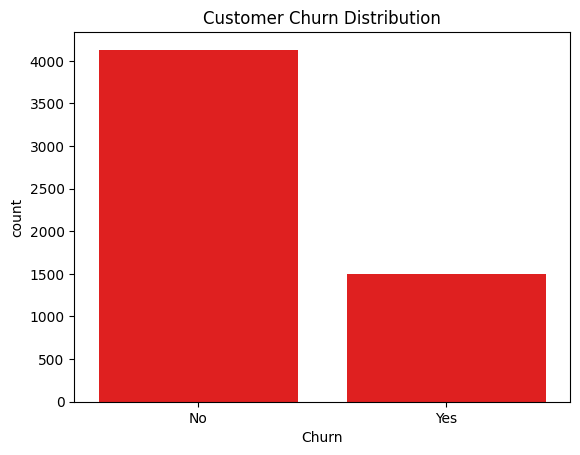

In [ ]:
sns.countplot(data=train, x="Churn",color = 'red')
plt.title("Customer Churn Distribution")
plt.show()

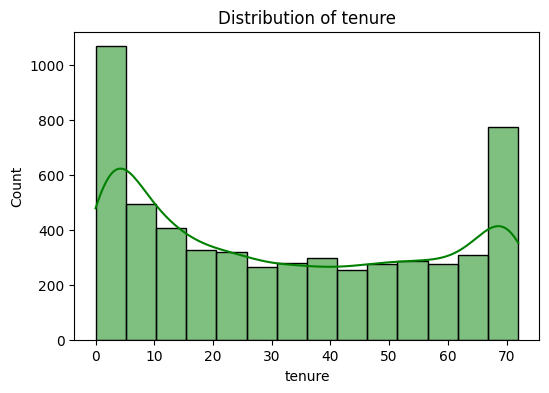

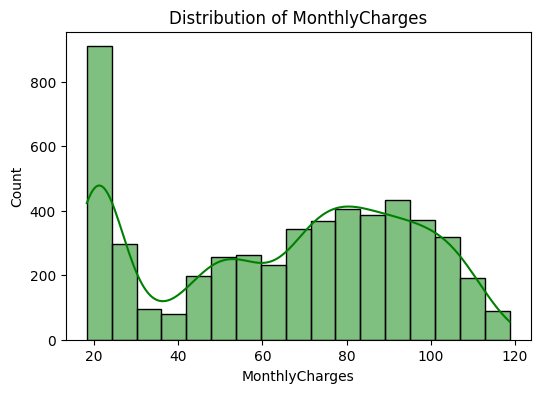

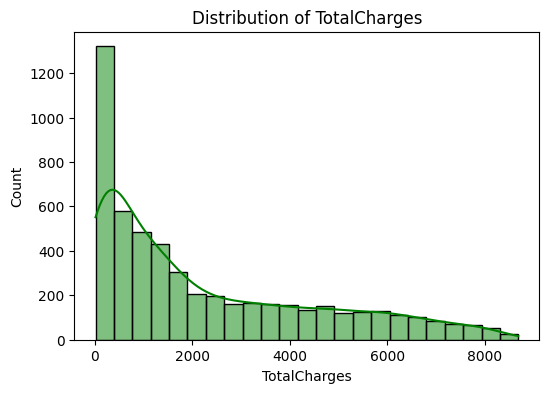

In [ ]:
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in numerical_columns:
    train[col] = pd.to_numeric(train[col], errors="coerce")

    plt.figure(figsize=(6, 4))
    sns.histplot(train[col], kde=True,color = 'green')
    plt.title(f"Distribution of {col}")
    plt.show()

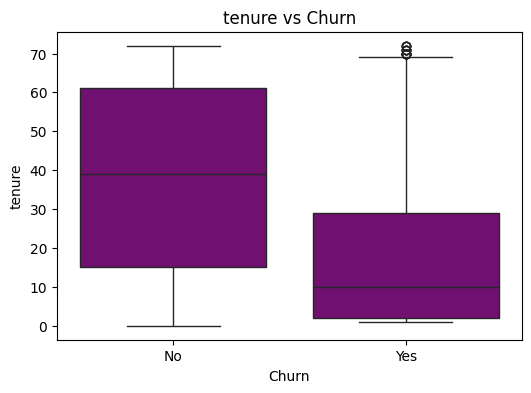

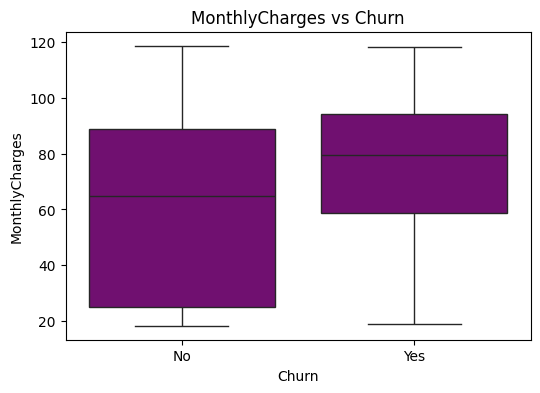

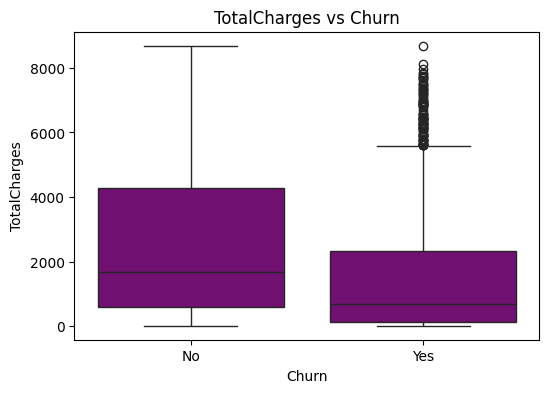

In [ ]:
for col in numerical_columns:

    plt.figure(figsize=(6, 4))

    sns.boxplot(
        data=train,
        x="Churn",
        y=col,
        color = 'purple'
    )

    plt.title(f"{col} vs Churn")
    plt.show()

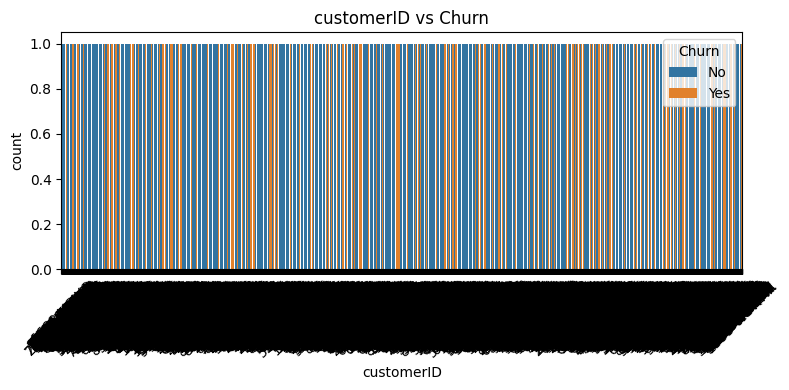

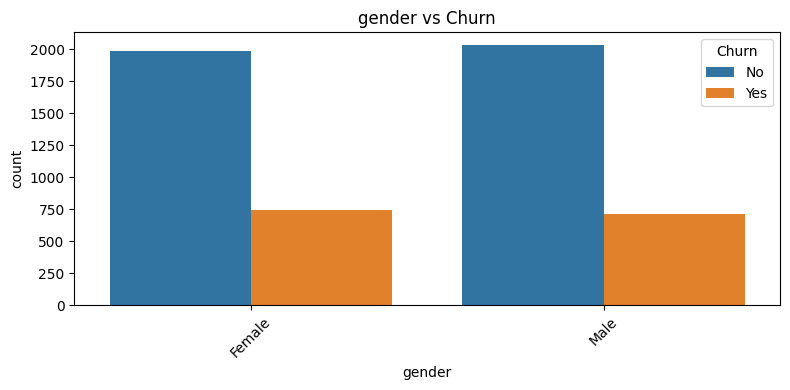

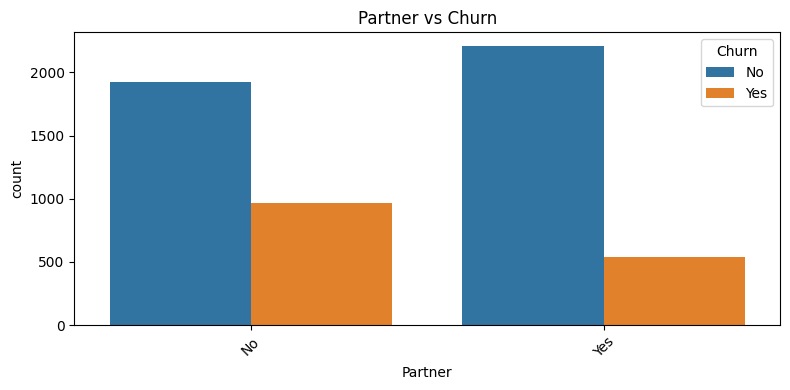

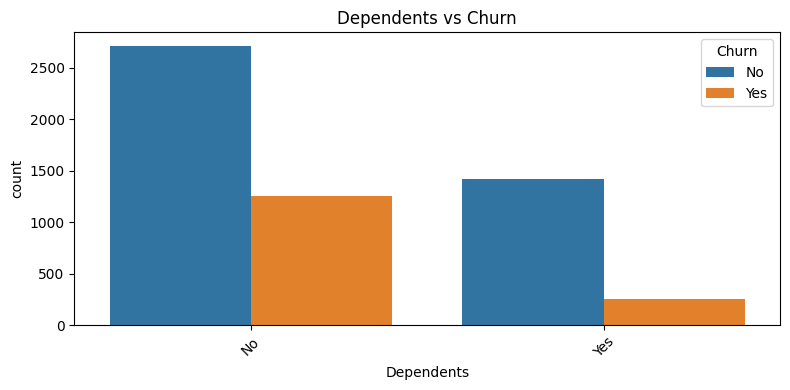

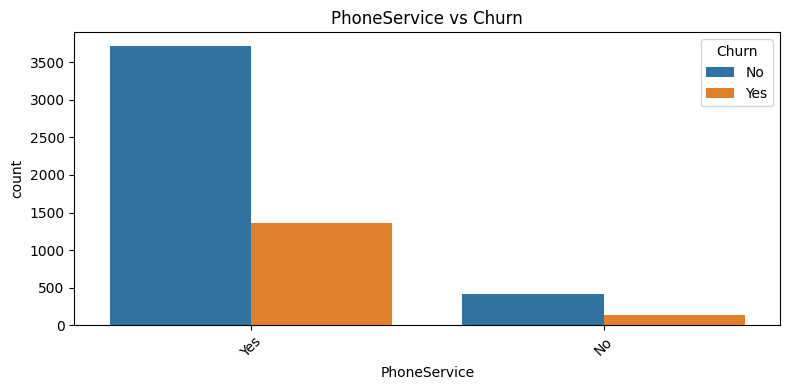

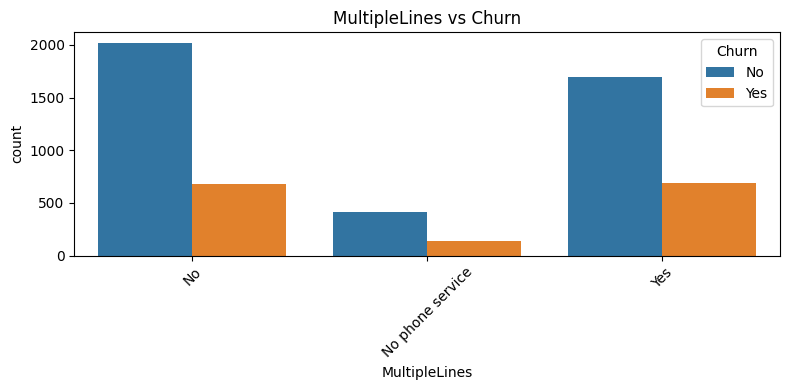

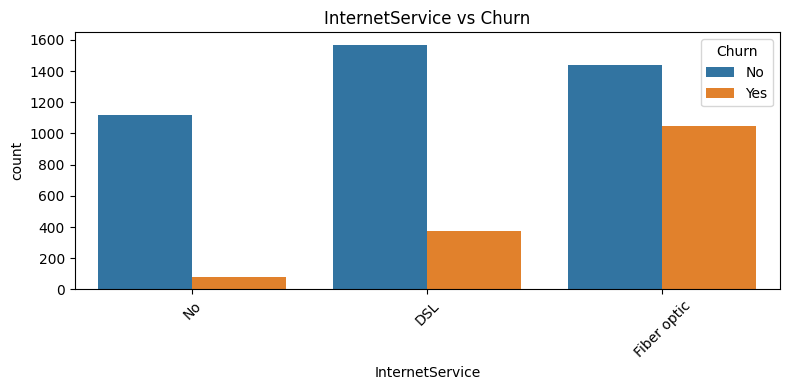

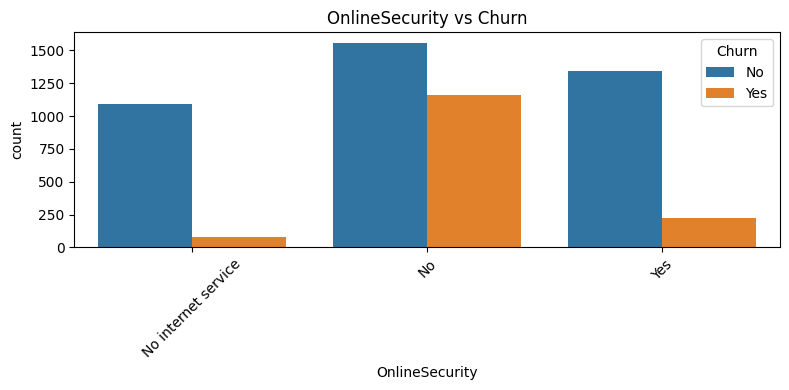

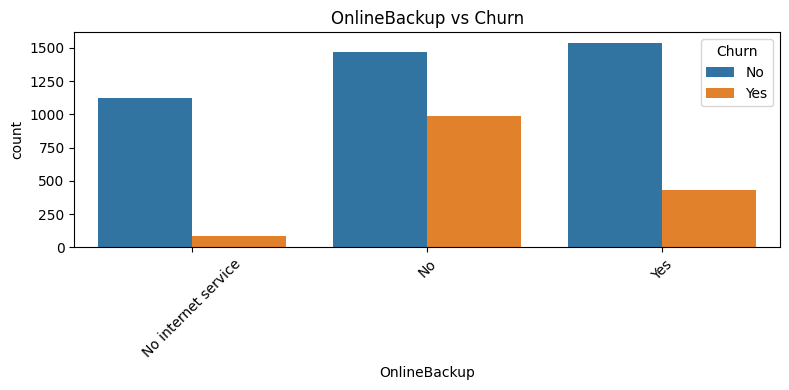

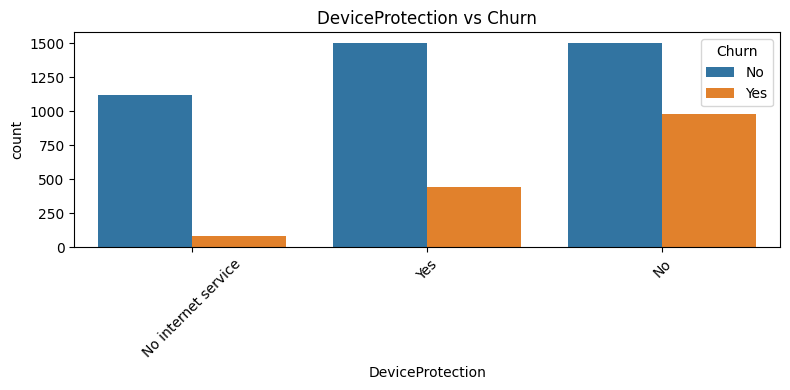

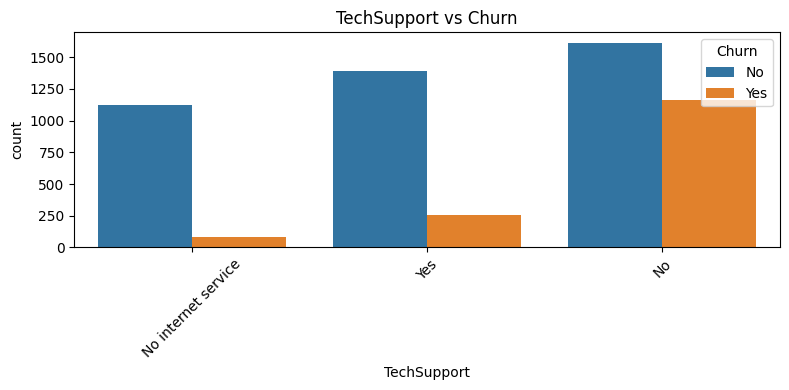

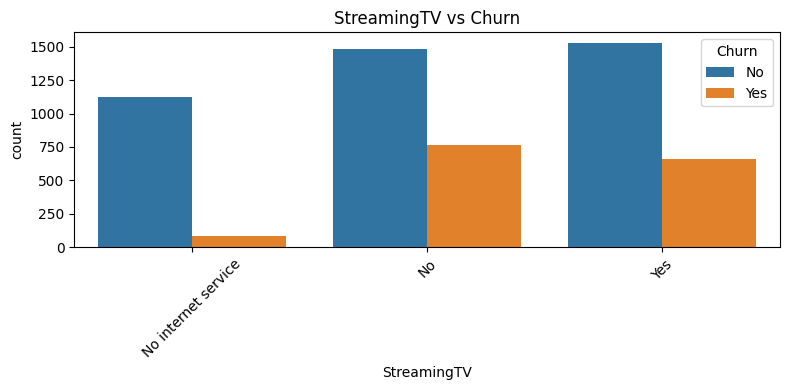

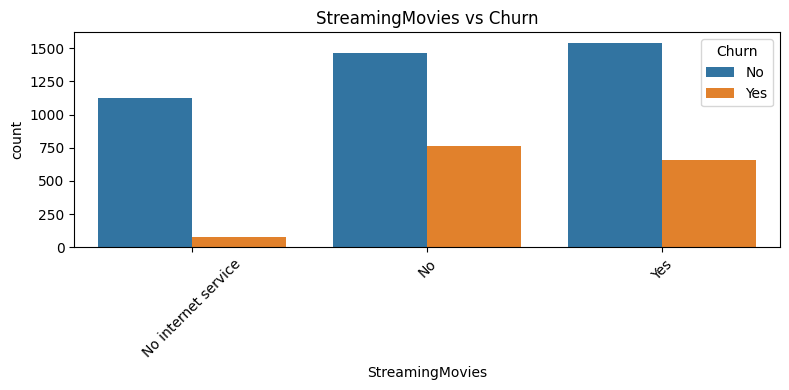

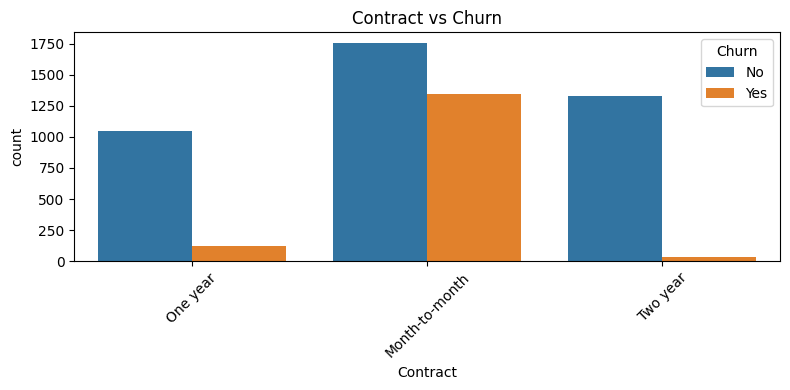

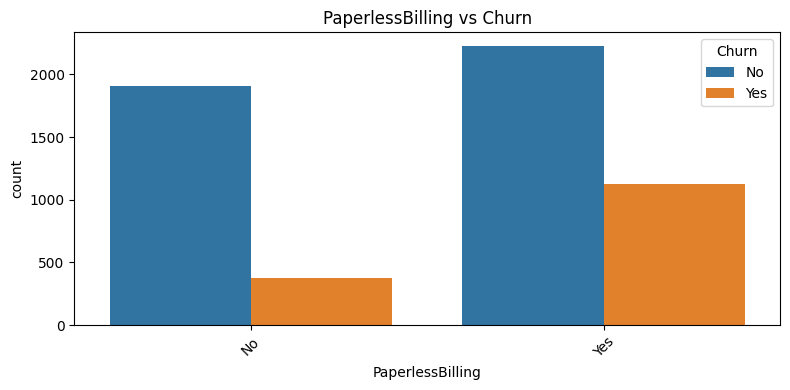

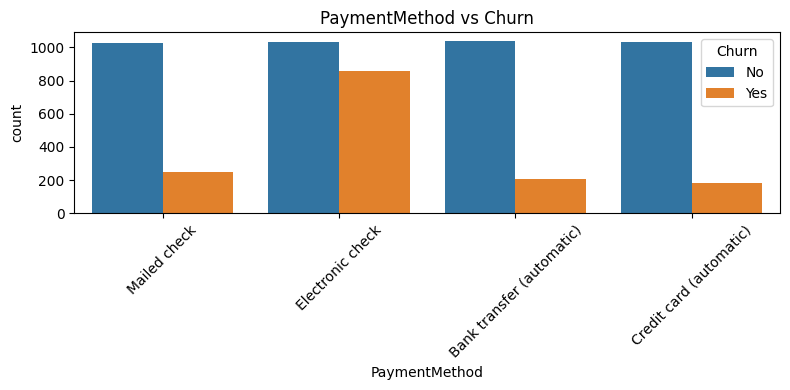

In [ ]:
categorical_columns = train.select_dtypes(
    include="object"
).columns.tolist()

categorical_columns.remove("Churn")

for col in categorical_columns:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=train,
        x=col,
        hue="Churn"
    )

    plt.title(f"{col} vs Churn")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

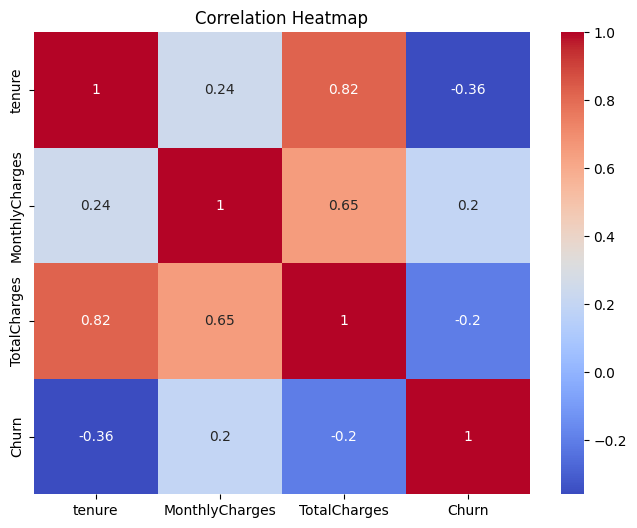

In [ ]:
numeric_data = train[
    numerical_columns
].copy()

numeric_data["Churn"] = train["Churn"].map({
    "Yes": 1,
    "No": 0
})

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

4. Data preprocessing

In [ ]:
train["TotalCharges"] = pd.to_numeric(
    train["TotalCharges"],
    errors="coerce"
)

test["TotalCharges"] = pd.to_numeric(
    test["TotalCharges"],
    errors="coerce"
)

In [ ]:
print(train.isnull().sum())

customerID            0
gender              169
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity      169
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges      394
TotalCharges        290
Churn                 0
dtype: int64


5. Feature engineering

In [ ]:
def feature_engineering(df):
    df = df.copy()

    # Ensure column names are referenced with correct lowercase 'tenure'
    # Customer lifetime value approximation
    df["CustomerLifetimeValue"] = df["tenure"] * df["MonthlyCharges"]

    # Average monthly charges based on tenure
    df["AverageMonthlyCharges"] = df["TotalCharges"] / df["tenure"].replace(0, np.nan)

    # Customer tenure groups
    df["TenureGroup"] = pd.cut(
        df["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Short", "Medium", "Long"]
    )

    return df

In [ ]:

train = feature_engineering(train)
test = feature_engineering(test)

train.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerLifetimeValue,AverageMonthlyCharges,TenureGroup
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,One year,No,Mailed check,20.75,700.45,No,726.25,20.012857,Medium
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Mailed check,35.75,961.40,No,1001.00,34.335714,Medium
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No,5521.60,99.661607,Long
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790.00,No,797.55,20.256410,Medium
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,One year,Yes,Bank transfer (automatic),51.25,2151.60,No,2203.75,50.037209,Medium


6. Prepare features and target

In [ ]:
# Remove CustomerID because it is only an identifier

train = train.drop(
    columns=["CustomerID"],
    errors="ignore"
)

test = test.drop(
    columns=["CustomerID"],
    errors="ignore"
)

In [ ]:
# Separate input features and target

X = train.drop(columns=["Churn"])

y = train["Churn"].map({
    "Yes": 1,
    "No": 0
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5634, 23)
Target shape: (5634,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (4507, 23)
X_val: (1127, 23)


7. Encode categorical variables and scale numerical variable

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'CustomerLifetimeValue', 'AverageMonthlyCharges']
Categorical features: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [ ]:
# Numerical preprocessing

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

8. Model development

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [ ]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully")

Logistic Regression trained successfully
Random Forest trained successfully
Gradient Boosting trained successfully


9. Model evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_val)

    y_prob = model.predict_proba(X_val)[:, 1]

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_val,
        y_prob
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.771074,0.551069,0.770764,0.642659,0.847832
1,Random Forest,0.804791,0.676856,0.514950,0.584906,0.839090
2,Gradient Boosting,0.810115,0.674699,0.558140,0.610909,0.851063


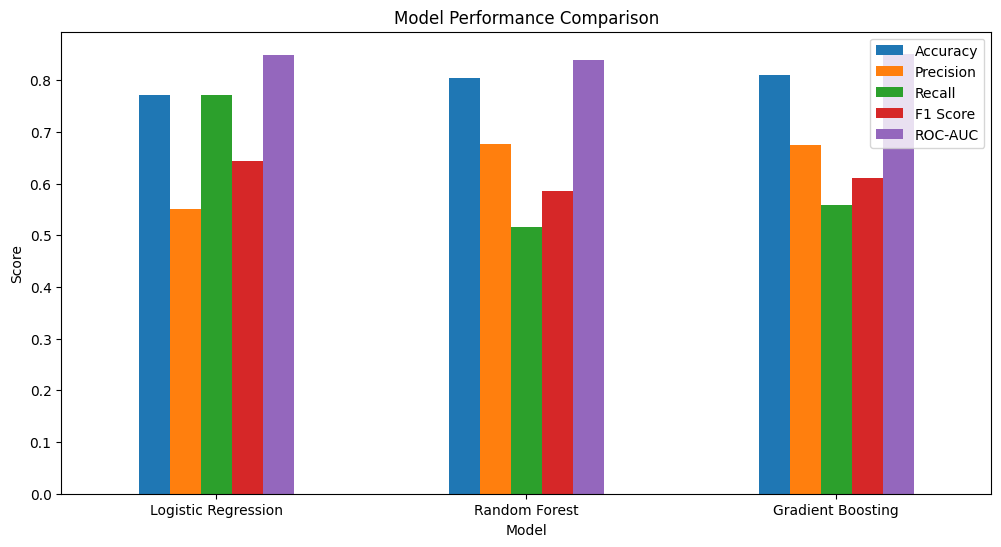

In [ ]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

In [ ]:
for name, model in trained_models.items():

    print("\nModel:", name)

    y_pred = model.predict(X_val)

    print(
        classification_report(
            y_val,
            y_pred,
            target_names=["No Churn", "Churn"]
        )
    )


Model: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83       826
       Churn       0.55      0.77      0.64       301

    accuracy                           0.77      1127
   macro avg       0.73      0.77      0.74      1127
weighted avg       0.81      0.77      0.78      1127


Model: Random Forest
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87       826
       Churn       0.68      0.51      0.58       301

    accuracy                           0.80      1127
   macro avg       0.76      0.71      0.73      1127
weighted avg       0.79      0.80      0.80      1127


Model: Gradient Boosting
              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87       826
       Churn       0.67      0.56      0.61       301

    accuracy                           0.81      1127
   macro avg       0.76      0.73      0.74      112

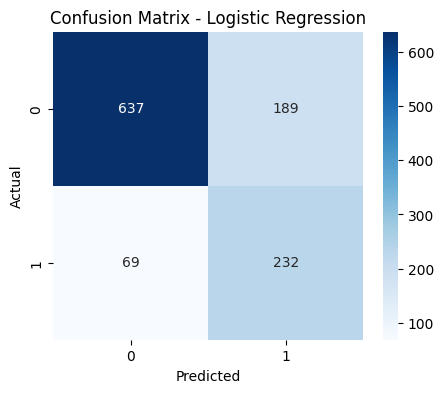

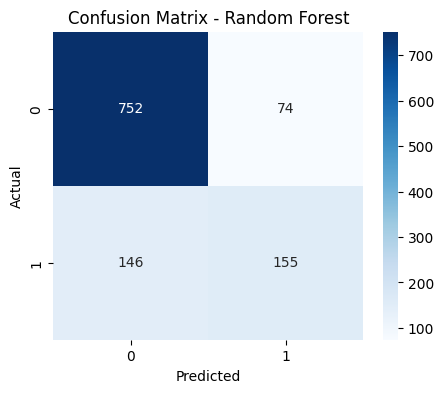

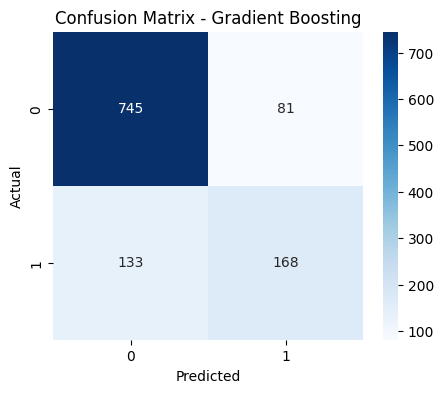

In [ ]:
for name, model in trained_models.items():

    y_pred = model.predict(X_val)

    cm = confusion_matrix(y_val, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

10. Feature selection and feature importance

In [ ]:
rf_model = trained_models["Random Forest"]

feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    rf_model
    .named_steps["model"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(15)

,Feature,Importance
1,num__tenure,0.060392
4,num__CustomerLifetimeValue,0.058505
3,num__TotalCharges,0.057616
2,num__MonthlyCharges,0.053754
5,num__AverageMonthlyCharges,0.051182
4545,cat__Contract_Month-to-month,0.042814
4547,cat__Contract_Two year,0.027255
4536,cat__TechSupport_No,0.022773
4527,cat__OnlineSecurity_No,0.020053
4556,cat__TenureGroup_New,0.019734


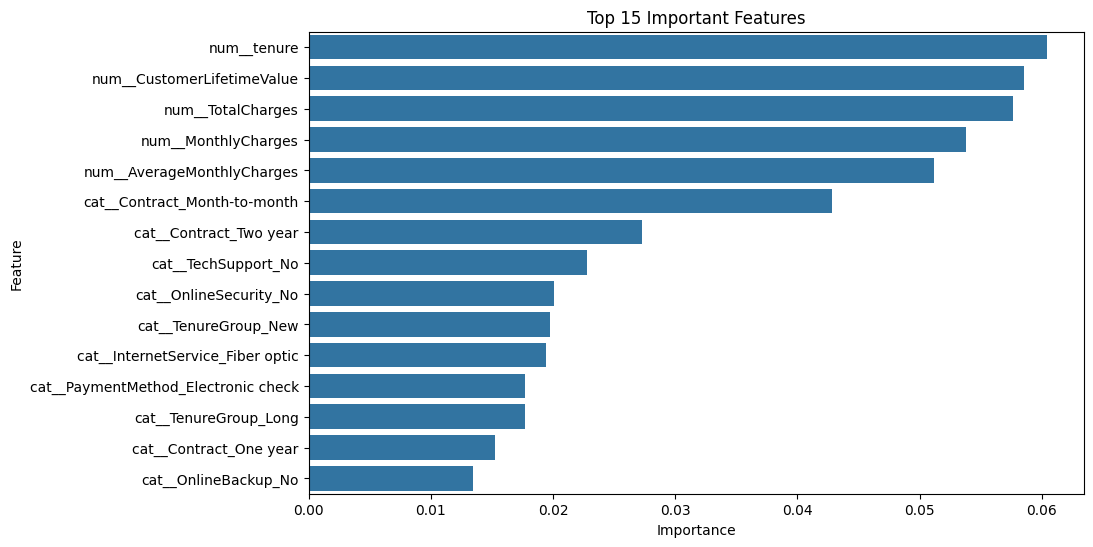

In [ ]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.show()

11. Hyperparameter tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        (
            "model",
            RandomForestClassifier(
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

In [ ]:
param_grid = {
    "model__n_estimators": [100, 200],

    "model__max_depth": [None, 10, 20],

    "model__min_samples_split": [2, 5],

    "model__min_samples_leaf": [1, 2]
}

In [ ]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges',
                                                                          'CustomerLifetimeValue',
                                                                          'AverageMonthlyCharges']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(stra...
                                                                          'StreamingTV',
                                                                          'StreamingMovies',
                                                                          'Contract',
                                                                          'PaperlessBilling',
                                                                          'PaymentMethod',
                                                                          'TenureGroup'])])),
                                       ('model',
                                        RandomForestClassifier(class_weight='balanced',
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 10, 20],
                         'model__min_samples_leaf': [1, 2],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='roc_auc', verbose=1)

In [ ]:
print("Best Parameters:")

print(grid_search.best_params_)

Best Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}


In [ ]:
print("Best Cross-Validation ROC-AUC:")

print(grid_search.best_score_)

Best Cross-Validation ROC-AUC:
0.8455807879492347


In [ ]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_val)

y_prob_tuned = best_model.predict_proba(X_val)[:, 1]

print(
    classification_report(
        y_val,
        y_pred_tuned,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.79      0.84       826
       Churn       0.57      0.76      0.65       301

    accuracy                           0.78      1127
   macro avg       0.74      0.78      0.75      1127
weighted avg       0.81      0.78      0.79      1127



In [ ]:
print(
    "Tuned Accuracy:",
    accuracy_score(y_val, y_pred_tuned)
)

print(
    "Tuned ROC-AUC:",
    roc_auc_score(y_val, y_prob_tuned)
)

Tuned Accuracy: 0.782608695652174
Tuned ROC-AUC: 0.8504138746551045


In [ ]:
before_tuning = trained_models["Random Forest"]

before_pred = before_tuning.predict(X_val)

before_prob = before_tuning.predict_proba(X_val)[:, 1]

comparison = pd.DataFrame({
    "Model": [
        "Random Forest Before Tuning",
        "Random Forest After Tuning"
    ],

    "Accuracy": [
        accuracy_score(y_val, before_pred),
        accuracy_score(y_val, y_pred_tuned)
    ],

    "F1 Score": [
        f1_score(y_val, before_pred),
        f1_score(y_val, y_pred_tuned)
    ],

    "ROC-AUC": [
        roc_auc_score(y_val, before_prob),
        roc_auc_score(y_val, y_prob_tuned)
    ]
})

comparison

,Model,Accuracy,F1 Score,ROC-AUC
0,Random Forest Before Tuning,0.804791,0.584906,0.839090
1,Random Forest After Tuning,0.782609,0.652482,0.850414


12. Final model training and testing

In [ ]:
final_model = grid_search.best_estimator_

final_model.fit(X, y)

print("Final model trained successfully")

Final model trained successfully


In [ ]:
if "Churn" in test.columns:

    X_test = test.drop(columns=["Churn"])

    y_test = test["Churn"].map({
        "Yes": 1,
        "No": 0
    })

else:

    X_test = test.copy()

In [ ]:
test_predictions = final_model.predict(X_test)

test_probabilities = final_model.predict_proba(X_test)[:, 1]

print("Predictions completed")

Predictions completed


In [ ]:
if "Churn" in test.columns:

    print(
        classification_report(
            y_test,
            test_predictions,
            target_names=["No Churn", "Churn"]
        )
    )

    print(
        "Testing Accuracy:",
        accuracy_score(y_test, test_predictions)
    )

    print(
        "Testing ROC-AUC:",
        roc_auc_score(y_test, test_probabilities)
    )

              precision    recall  f1-score   support

    No Churn       0.89      0.76      0.82      1044
       Churn       0.51      0.72      0.60       365

    accuracy                           0.75      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.79      0.75      0.76      1409

Testing Accuracy: 0.7494677075940384
Testing ROC-AUC: 0.8249107752060043


In [ ]:
final_results = pd.DataFrame({
    "CustomerID": test["CustomerID"]
        if "CustomerID" in test.columns
        else np.arange(len(test)),

    "Actual_Churn": test["Churn"]
        if "Churn" in test.columns
        else "Not Available",

    "Predicted_Churn": np.where(
        test_predictions == 1,
        "Yes",
        "No"
    ),

    "Churn_Probability": test_probabilities
})

final_results.head()

,CustomerID,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,No,Yes,0.616668
1,1,No,No,0.383216
2,2,Yes,No,0.476603
3,3,No,No,0.234897
4,4,No,Yes,0.508419


In [ ]:
final_results.to_csv(
    "Customer_Churn_Predictions.csv",
    index=False
)

print("Prediction file saved successfully")

Prediction file saved successfully


13. Conclusion

## Conclusion

In this project, machine learning models were developed to predict customer churn. The models were evaluated and compared to identify the best-performing model. The final model helps identify customers who are likely to leave the company.

## Key Findings
- Customer behavior and contract details influence churn.
- Machine learning can help predict customer churn.
- The best model was selected based on evaluation metrics.

## Business Recommendations
- Provide special offers to high-risk customers.
- Improve customer service and satisfaction.
- Encourage customers to choose long-term contracts.
- Monitor customer churn regularly.